In [2]:
import os
import pandas as pd
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
engine = create_engine(os.environ["DB_URL"])
df = pd.read_sql("SELECT * FROM loan_features", engine)
print(df.shape, df["default_flag"].sum())

(682, 44) 76


In [3]:
# Add region from the district table (via the account), and an under-18 flag
regions = pd.read_sql("""
    SELECT a.account_id, d.region
    FROM account a
    JOIN district d ON d.district_id = a.district_id
""", engine)

df = df.merge(regions, on="account_id", how="left")
df["is_minor"] = (df["age_at_loan"] < 18).astype(int)

# Target: 1 = default, 0 = no default
y = df["default_flag"]

# Features: drop the outcome, identifiers and raw dates
drop_cols = ["default_flag", "status", "loan_id", "account_id", "loan_date"]
X = df.drop(columns=drop_cols)

# Turn categories (gender, frequency, region) into 0/1 columns
X = pd.get_dummies(X, columns=["gender", "statement_frequency", "region"], drop_first=True, dtype=int)

print(X.shape, y.sum())
print(X.columns.tolist())

(682, 48) 76
['loan_amount', 'duration', 'payments', 'age_at_loan', 'account_age_months', 'history_months', 'has_card_at_grant', 'avg_salary', 'unemployment_rate_95', 'entrepreneurs_per_1000', 'crimes_95', 'urban_ratio', 'inhabitants', 'avg_balance_3m', 'avg_balance_6m', 'avg_balance_12m', 'sd_balance_3m', 'sd_balance_6m', 'min_balance_3m', 'min_balance_6m', 'pct_days_negative_6m', 'balance_at_grant', 'balance_change_90d', 'monthly_inflow_3m', 'monthly_outflow_3m', 'monthly_inflow_6m', 'monthly_outflow_6m', 'n_credits_6m', 'n_debits_6m', 'cash_out_6m', 'n_penalty_interest_12m', 'has_pension_12m', 'payment_to_inflow_6m', 'loan_to_annual_salary', 'inflow_outflow_ratio_6m', 'cash_share_of_outflow_6m', 'balance_to_loan', 'is_minor', 'gender_M', 'statement_frequency_monthly', 'statement_frequency_weekly', 'region_central Bohemia', 'region_east Bohemia', 'region_north Bohemia', 'region_north Moravia', 'region_south Bohemia', 'region_south Moravia', 'region_west Bohemia']


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

print("Columns with missing values:")
print(X.isna().sum()[lambda s: s > 0])

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = cross_validate(baseline, X, y, cv=cv,
                        scoring=["roc_auc", "average_precision"])

print("ROC-AUC:", round(scores["test_roc_auc"].mean(), 3),
      "+/-", round(scores["test_roc_auc"].std(), 3))
print("PR-AUC: ", round(scores["test_average_precision"].mean(), 3),
      "+/-", round(scores["test_average_precision"].std(), 3))

Columns with missing values:
unemployment_rate_95        8
crimes_95                   8
inflow_outflow_ratio_6m     3
cash_share_of_outflow_6m    3
dtype: int64
ROC-AUC: 0.885 +/- 0.045
PR-AUC:  0.62 +/- 0.117


In [5]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# Flag accounts with no outflow in 6 months, where the ratios are undefined
X["no_outflow_6m"] = df["monthly_outflow_6m"].eq(0).astype(int)

def run_baseline(features, label):
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
    )
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
    scores = cross_validate(model, features, y, cv=cv,
                            scoring=["roc_auc", "average_precision"])
    roc = scores["test_roc_auc"]
    pr = scores["test_average_precision"]
    print(f"{label}")
    print(f"  ROC-AUC: {roc.mean():.3f} +/- {roc.std():.3f}")
    print(f"  PR-AUC:  {pr.mean():.3f} +/- {pr.std():.3f}")
    print()

distress = ["n_penalty_interest_12m", "pct_days_negative_6m"]

run_baseline(X, "All features")
run_baseline(X.drop(columns=distress), "Without distress flags")

All features
  ROC-AUC: 0.885 +/- 0.044
  PR-AUC:  0.620 +/- 0.116

Without distress flags
  ROC-AUC: 0.867 +/- 0.048
  PR-AUC:  0.579 +/- 0.114



In [6]:
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
    )

# Fit once on all loans to get the point estimates
full = make_model().fit(X, y)
coef_full = full[-1].coef_[0]

# Bootstrap: refit on resampled loans to estimate the uncertainty
rng = np.random.default_rng(42)
B = 1000
boot = np.zeros((B, X.shape[1]))
for b in range(B):
    idx = rng.choice(len(y), size=len(y), replace=True)
    m = make_model().fit(X.iloc[idx], y.iloc[idx])
    boot[b] = m[-1].coef_[0]

table = pd.DataFrame({
    "coef": coef_full,
    "ci_low": np.percentile(boot, 2.5, axis=0),
    "ci_high": np.percentile(boot, 97.5, axis=0),
}, index=X.columns)
table["significant"] = (table["ci_low"] > 0) | (table["ci_high"] < 0)
table["abs_coef"] = table["coef"].abs()

top = table.sort_values("abs_coef", ascending=False).head(15).drop(columns="abs_coef")
print(top.round(3).to_string())

                           coef  ci_low  ci_high  significant
cash_share_of_outflow_6m  0.787   0.553    1.088         True
n_penalty_interest_12m    0.592   0.159    1.016         True
pct_days_negative_6m      0.520   0.245    0.808         True
avg_balance_12m          -0.507  -0.798   -0.148         True
min_balance_6m           -0.453  -0.977   -0.087         True
sd_balance_6m             0.427   0.052    0.798         True
avg_balance_6m           -0.406  -0.703   -0.096         True
n_debits_6m              -0.389  -0.781   -0.055         True
min_balance_3m           -0.387  -0.793   -0.076         True
n_credits_6m              0.345   0.073    0.629         True
has_card_at_grant        -0.336  -0.456   -0.163         True
unemployment_rate_95     -0.329  -0.655    0.032        False
region_north Bohemia     -0.308  -0.580   -0.123         True
payment_to_inflow_6m      0.281  -0.066    0.567        False
entrepreneurs_per_1000   -0.255  -0.577    0.123        False


In [7]:
# Bootstrap p-value: the share of resamples on the opposite side of zero
# from the point estimate, doubled for a two-sided test
p_low = (boot <= 0).mean(axis=0)
p_high = (boot >= 0).mean(axis=0)
table["p_boot"] = np.minimum(2 * np.minimum(p_low, p_high), 1.0)

top = (table.sort_values("p_boot")
            .head(15)
            .drop(columns=["significant", "abs_coef"], errors="ignore"))
print(top.round(3).to_string())

                           coef  ci_low  ci_high  p_boot
has_card_at_grant        -0.336  -0.456   -0.163   0.000
pct_days_negative_6m      0.520   0.245    0.808   0.000
region_north Bohemia     -0.308  -0.580   -0.123   0.000
cash_share_of_outflow_6m  0.787   0.553    1.088   0.000
n_penalty_interest_12m    0.592   0.159    1.016   0.006
avg_balance_12m          -0.507  -0.798   -0.148   0.006
avg_balance_6m           -0.406  -0.703   -0.096   0.010
min_balance_6m           -0.453  -0.977   -0.087   0.010
min_balance_3m           -0.387  -0.793   -0.076   0.014
n_credits_6m              0.345   0.073    0.629   0.016
history_months           -0.216  -0.405   -0.032   0.018
account_age_months       -0.216  -0.405   -0.032   0.018
n_debits_6m              -0.389  -0.781   -0.055   0.030
sd_balance_6m             0.427   0.052    0.798   0.030
loan_amount               0.237   0.011    0.451   0.042


In [8]:
X[["history_months", "account_age_months"]].corr()

,history_months,account_age_months
history_months,1.0,1.0
account_age_months,1.0,1.0


In [9]:
X = X.drop(columns=["history_months"])
print(X.shape)

(682, 48)


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

print("Feature matrix:", X.shape, "| defaults:", y.sum())

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = cross_validate(baseline, X, y, cv=cv,
                        scoring=["roc_auc", "average_precision"])

roc = scores["test_roc_auc"]
pr = scores["test_average_precision"]
print(f"ROC-AUC: {roc.mean():.3f} +/- {roc.std():.3f}")
print(f"PR-AUC:  {pr.mean():.3f} +/- {pr.std():.3f}")

Feature matrix: (682, 48) | defaults: 76


ROC-AUC: 0.885 +/- 0.045
PR-AUC:  0.619 +/- 0.116


In [11]:
import numpy as np
import pandas as pd

results = []
for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=5000),
    )
    s = cross_validate(model, X, y, cv=cv,
                       scoring=["roc_auc", "average_precision"])
    results.append({
        "C": C,
        "ROC-AUC": s["test_roc_auc"].mean(),
        "ROC-AUC sd": s["test_roc_auc"].std(),
        "PR-AUC": s["test_average_precision"].mean(),
        "PR-AUC sd": s["test_average_precision"].std(),
    })

summary = pd.DataFrame(results).round(3)
print(summary.to_string(index=False))

    C  ROC-AUC  ROC-AUC sd  PR-AUC  PR-AUC sd
 0.01    0.895       0.050   0.658      0.117
 0.03    0.892       0.046   0.639      0.118
 0.10    0.885       0.045   0.619      0.116
 0.30    0.877       0.044   0.606      0.117
 1.00    0.871       0.043   0.597      0.115
 3.00    0.867       0.043   0.591      0.115
10.00    0.866       0.044   0.592      0.113


In [12]:
results = []
for C in [0.001, 0.003, 0.01, 0.03, 0.1]:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=5000),
    )
    s = cross_validate(model, X, y, cv=cv,
                       scoring=["roc_auc", "average_precision"])
    results.append({
        "C": C,
        "ROC-AUC": s["test_roc_auc"].mean(),
        "PR-AUC": s["test_average_precision"].mean(),
        "PR-AUC sd": s["test_average_precision"].std(),
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

    C  ROC-AUC  PR-AUC  PR-AUC sd
0.001    0.881   0.655      0.121
0.003    0.891   0.662      0.121
0.010    0.895   0.658      0.117
0.030    0.892   0.639      0.118
0.100    0.885   0.619      0.116


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic (C=0.01)": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=0.01, class_weight="balanced", max_iter=5000),
    ),
    "Random forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1,
        ),
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=(y == 0).sum() / (y == 1).sum(),  # about 8, balances classes
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
}

rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv,
                       scoring=["roc_auc", "average_precision"])
    rows.append({
        "Model": name,
        "ROC-AUC": s["test_roc_auc"].mean(),
        "ROC-AUC sd": s["test_roc_auc"].std(),
        "PR-AUC": s["test_average_precision"].mean(),
        "PR-AUC sd": s["test_average_precision"].std(),
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))

            Model  ROC-AUC  ROC-AUC sd  PR-AUC  PR-AUC sd
Logistic (C=0.01)    0.895       0.050   0.658      0.117
    Random forest    0.910       0.042   0.676      0.104
          XGBoost    0.918       0.039   0.679      0.115


In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

fold_scores = {}
for name, model in models.items():
    fold_scores[name] = cross_val_score(model, X, y, cv=cv, scoring="average_precision")

diff = fold_scores["XGBoost"] - fold_scores["Logistic (C=0.01)"]
print(f"XGBoost minus logistic, PR-AUC: mean {diff.mean():.3f}, "
      f"XGBoost better in {(diff > 0).mean():.0%} of folds")

XGBoost minus logistic, PR-AUC: mean 0.021, XGBoost better in 56% of folds


In [ ]:
rf_diff = fold_scores["Random forest"] - fold_scores["Logistic (C=0.01)"]
print(f"Random forest minus logistic, PR-AUC: mean {rf_diff.mean():.3f}, "
      f"random forest better in {(rf_diff > 0).mean():.0%} of folds")

Random forest minus logistic, PR-AUC: mean 0.018, random forest better in 60% of folds


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Business model: unweighted, so probabilities approximate real default rates
risk_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=5000),
)

# Out-of-fold probabilities: each loan is scored by a model that never saw it.
# Averaged over 10 different fold splits to reduce split-to-split noise.
oof = np.zeros(len(y))
for seed in range(10):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof += cross_val_predict(risk_model, X, y, cv=skf, method="predict_proba")[:, 1]
oof /= 10

scores = pd.DataFrame({"loan_id": df["loan_id"], "pd_score": oof, "default_flag": y})
print("Mean predicted PD:", round(oof.mean(), 3),
      "| observed default rate:", round(y.mean(), 3))

# Risk bands: deciles, band 1 = lowest predicted risk, band 10 = highest
scores["band"] = pd.qcut(scores["pd_score"], 10, labels=range(1, 11))
overall_rate = y.mean()
bands = (scores.groupby("band", observed=True)
         .agg(loans=("default_flag", "size"),
              defaults=("default_flag", "sum"),
              avg_pd=("pd_score", "mean")))
bands["default_rate"] = bands["defaults"] / bands["loans"]
bands["lift"] = bands["default_rate"] / overall_rate
bands["share_of_defaults"] = bands["defaults"] / bands["defaults"].sum()
print(bands.round(3).to_string())

# Cut-off table: what a decline rule would catch and cost
rows = []
for cut in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    flagged = scores["pd_score"] >= cut
    caught = scores.loc[flagged, "default_flag"].sum()
    rows.append({
        "cutoff": cut,
        "loans_declined": int(flagged.sum()),
        "defaults_caught": int(caught),
        "share_of_defaults_caught": round(caught / y.sum(), 3),
        "good_loans_declined": int((flagged & (y == 0)).sum()),
        "default_rate_declined": round(caught / max(flagged.sum(), 1), 3),
    })
print(pd.DataFrame(rows).to_string(index=False))

Mean predicted PD: 0.111 | observed default rate: 0.111
      loans  defaults  avg_pd  default_rate   lift  share_of_defaults
band                                                                 
1        69         1   0.018         0.014  0.130              0.013
2        68         1   0.034         0.015  0.132              0.013
3        68         2   0.045         0.029  0.264              0.026
4        68         0   0.056         0.000  0.000              0.000
5        68         1   0.068         0.015  0.132              0.013
6        68         1   0.084         0.015  0.132              0.013
7        68         5   0.104         0.074  0.660              0.066
8        68         7   0.130         0.103  0.924              0.092
9        68        15   0.173         0.221  1.979              0.197
10       69        43   0.394         0.623  5.592              0.566
 cutoff  loans_declined  defaults_caught  share_of_defaults_caught  good_loans_declined  default_rate_de

In [ ]:
out = scores[["loan_id", "pd_score", "band", "default_flag"]].copy()
out["band"] = out["band"].astype(int)
out["pd_score"] = out["pd_score"].round(4)

out.to_sql("loan_predictions", engine, if_exists="replace", index=False)

# Primary key, so Power BI can relate it to loan_features on loan_id
with engine.begin() as conn:
    conn.exec_driver_sql("ALTER TABLE loan_predictions ADD PRIMARY KEY (loan_id)")

check = pd.read_sql("SELECT COUNT(*) AS n, SUM(default_flag) AS defaults FROM loan_predictions", engine)
print(check)

     n  defaults
0  682      76.0


min_balance_6m              1.116
cash_share_of_outflow_6m    1.029
min_balance_3m              0.643
account_age_months          0.443
n_credits_6m                0.433
inflow_outflow_ratio_6m     0.398
sd_balance_6m               0.347
balance_at_grant            0.333
n_penalty_interest_12m      0.285
loan_amount                 0.245
avg_balance_12m             0.242
payments                    0.225
balance_to_loan             0.219
avg_balance_3m              0.217
monthly_inflow_3m           0.208


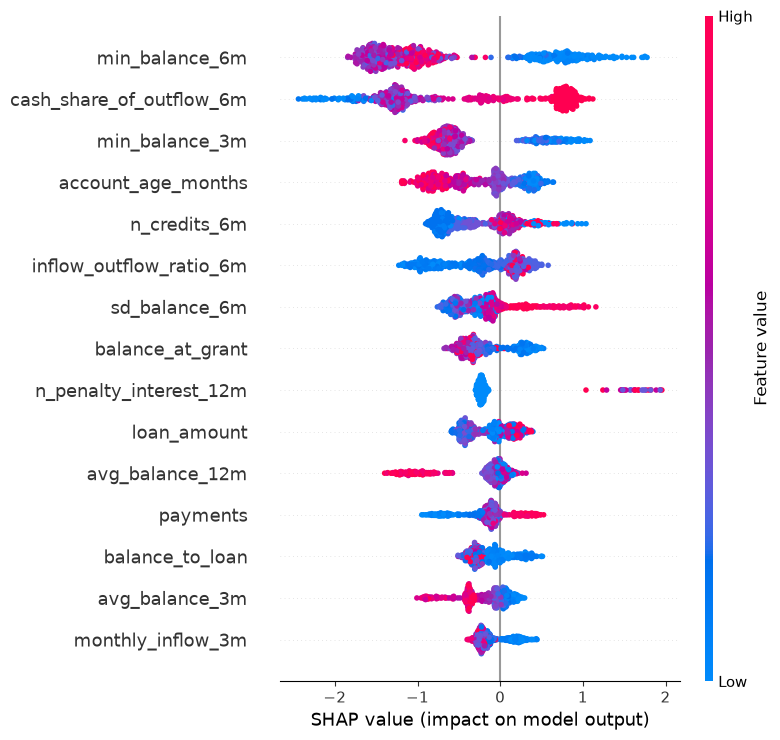

In [ ]:
import shap

xgb_full = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
    eval_metric="logloss", random_state=42, n_jobs=-1,
)
xgb_full.fit(X, y)

explainer = shap.TreeExplainer(xgb_full)
shap_values = explainer.shap_values(X)

# Average absolute impact per feature: a ranking of which features matter most
shap_importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=X.columns)
                   .sort_values(ascending=False))
print(shap_importance.head(15).round(3).to_string())

shap.summary_plot(shap_values, X, max_display=15)

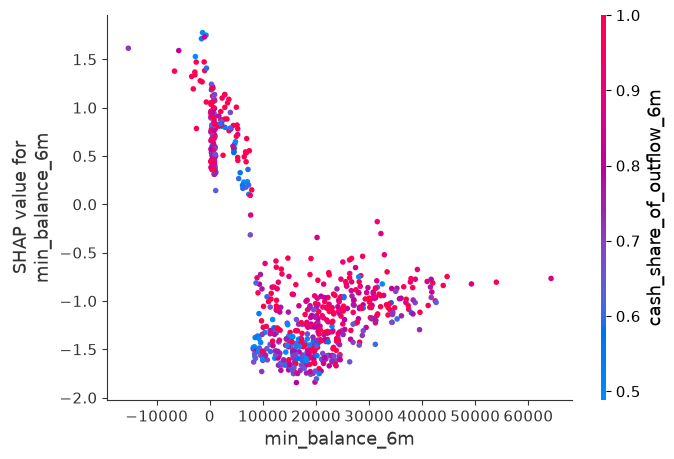

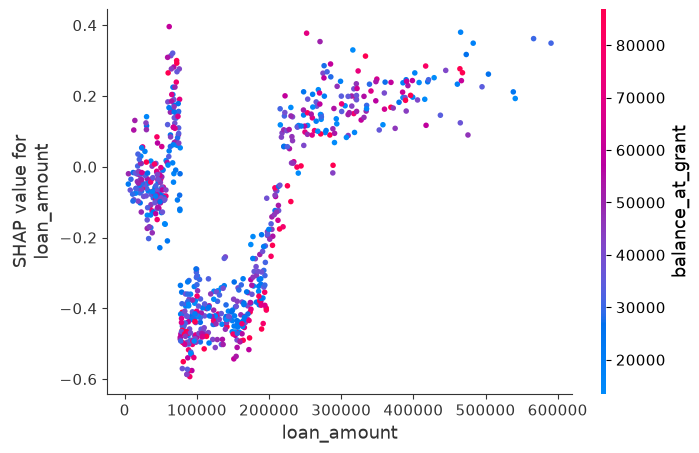

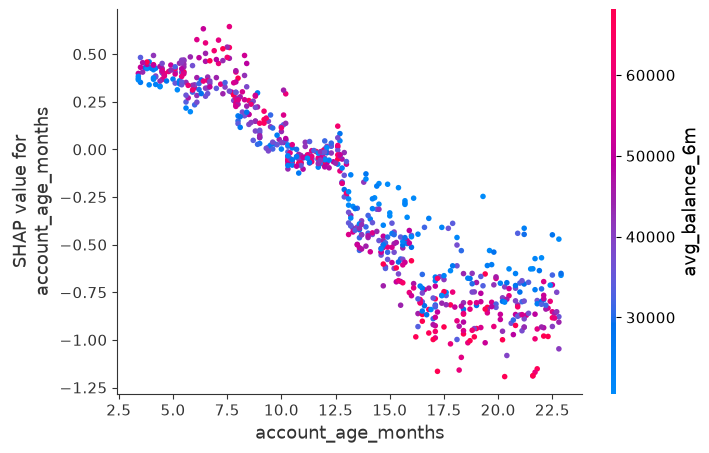

In [ ]:
# Shape of each effect: value on x-axis, risk push on y-axis
shap.dependence_plot("min_balance_6m", shap_values, X, interaction_index="cash_share_of_outflow_6m")
shap.dependence_plot("loan_amount", shap_values, X, interaction_index="balance_at_grant")
shap.dependence_plot("account_age_months", shap_values, X)

In [ ]:
bins = pd.cut(df["loan_amount"], [0, 80000, 200000, 1e9], labels=["under 80k", "80k-200k", "over 200k"])
print(pd.crosstab(bins, df["duration"]))
print(df.groupby(bins, observed=True)["default_flag"].mean().round(3))

duration      12  24  36  48  60
loan_amount                     
under 80k    102  57  32  21  16
80k-200k      29  80  64  53  43
over 200k      0   1  34  64  86
loan_amount
under 80k    0.079
80k-200k     0.086
over 200k    0.189
Name: default_flag, dtype: float64


In [14]:
print(scores.keys())
print(scores[list(scores.keys())[0]][:5])

dict_keys(['fit_time', 'score_time', 'test_roc_auc', 'test_average_precision'])
[0.06622529 0.04505277 0.03576255 0.04671621 0.03694081]


In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Logistic OOF
lr_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(C=0.01, max_iter=5000),
)
oof_lr = cross_val_predict(lr_model, X, y, cv=cv5, method="predict_proba")[:, 1]

# Random Forest OOF
rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                           class_weight="balanced_subsample", random_state=42, n_jobs=-1),
)
oof_rf = cross_val_predict(rf_model, X, y, cv=cv5, method="predict_proba")[:, 1]

# XGBoost OOF
xgb_model = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8,
                           scale_pos_weight=8, random_state=42, eval_metric="logloss")
oof_xgb = cross_val_predict(xgb_model, X, y, cv=cv5, method="predict_proba")[:, 1]

print("OOF probabilities computed.")
print(f"LR mean PD: {oof_lr.mean():.3f}")
print(f"RF mean PD: {oof_rf.mean():.3f}")
print(f"XGB mean PD: {oof_xgb.mean():.3f}")

OOF probabilities computed.
LR mean PD: 0.110
RF mean PD: 0.181
XGB mean PD: 0.122


In [20]:
def cutoff_table(oof_probs, y, model_name, cutoff=0.15):
    flagged = oof_probs >= cutoff
    caught = y[flagged].sum()
    declined = flagged.sum()
    good_declined = (flagged & (y == 0)).sum()
    return {
        "Model": model_name,
        "Declined": int(declined),
        "Defaults Caught": int(caught),
        "Catch Rate %": round(caught / y.sum() * 100, 1),
        "Good Declined": int(good_declined),
    }

cutoff = 0.15
rows = [
    cutoff_table(oof_lr, y, "Logistic Regression", cutoff),
    cutoff_table(oof_rf, y, "Random Forest", cutoff),
    cutoff_table(oof_xgb, y, "XGBoost", cutoff),
]

# Add two-stage manually (already computed)
rows.append({
    "Model": "Two-stage",
    "Declined": 91,
    "Defaults Caught": 49,
    "Catch Rate %": 64.5,
    "Good Declined": 42,
})

print(pd.DataFrame(rows).to_string(index=False))

              Model  Declined  Defaults Caught  Catch Rate %  Good Declined
Logistic Regression       126               57          75.0             69
      Random Forest       266               71          93.4            195
            XGBoost       120               59          77.6             61
          Two-stage        91               49          64.5             42


In [21]:
# Loan-level P&L calculation
LGD = 0.40  # assume bank loses 40% of loan amount on default

loan_pnl = df[["loan_id", "loan_amount", "duration", "payments", "default_flag"]].copy()
loan_pnl["interest_income"] = loan_pnl["payments"] * loan_pnl["duration"] - loan_pnl["loan_amount"]
loan_pnl["loss_if_default"] = loan_pnl["loan_amount"] * LGD
loan_pnl["net"] = loan_pnl.apply(
    lambda r: -r["loss_if_default"] if r["default_flag"] == 1 else r["interest_income"], axis=1
)

print(loan_pnl[["interest_income","loss_if_default","net"]].describe().round(0))
print(f"\nTotal portfolio net if approve all: {loan_pnl['net'].sum():,.0f} CZK")

       interest_income  loss_if_default       net
count            682.0            682.0     682.0
mean               0.0          60564.0   -9138.0
std                0.0          45349.0   31139.0
min                0.0           1992.0 -216480.0
25%                0.0          26693.0       0.0
50%                0.0          46771.0       0.0
75%                0.0          84262.0       0.0
max                0.0         236328.0       0.0

Total portfolio net if approve all: -6,232,061 CZK


In [22]:
LGD = 0.40
ANNUAL_RATE = 0.08

loan_pnl = df[["loan_id", "loan_amount", "duration", "payments", "default_flag"]].copy()

# Interest income = loan_amount * monthly_rate * duration (simple interest approximation)
monthly_rate = ANNUAL_RATE / 12
loan_pnl["interest_income"] = loan_pnl["loan_amount"] * monthly_rate * loan_pnl["duration"]
loan_pnl["loss_if_default"] = loan_pnl["loan_amount"] * LGD
loan_pnl["net"] = loan_pnl.apply(
    lambda r: -r["loss_if_default"] if r["default_flag"] == 1 else r["interest_income"], axis=1
)

print(f"Avg interest income per good loan: {loan_pnl.loc[loan_pnl['default_flag']==0,'interest_income'].mean():,.0f} CZK")
print(f"Avg loss per default: {loan_pnl['loss_if_default'].mean():,.0f} CZK")
print(f"\nTotal portfolio net if approve all: {loan_pnl['net'].sum():,.0f} CZK")

Avg interest income per good loan: 42,575 CZK
Avg loss per default: 60,564 CZK

Total portfolio net if approve all: 19,568,364 CZK


In [23]:
def model_pnl(oof_probs, y, loan_pnl, model_name, cutoff=0.15):
    approved = oof_probs < cutoff
    approved_pnl = loan_pnl.loc[approved, "net"].sum()
    declined_defaults = ((~approved) & (y == 1)).sum()
    declined_good = ((~approved) & (y == 0)).sum()
    return {
        "Model": model_name,
        "Approved": int(approved.sum()),
        "Net Profit (CZK)": int(approved_pnl),
        "Defaults Avoided": int(declined_defaults),
        "Good Loans Lost": int(declined_good),
    }

cutoff = 0.15
pnl_rows = [
    model_pnl(oof_lr,  y, loan_pnl, "Logistic Regression", cutoff),
    model_pnl(oof_rf,  y, loan_pnl, "Random Forest",       cutoff),
    model_pnl(oof_xgb, y, loan_pnl, "XGBoost",             cutoff),
]

# Baselines
pnl_rows.insert(0, {
    "Model": "Approve All (baseline)",
    "Approved": 682,
    "Net Profit (CZK)": int(loan_pnl["net"].sum()),
    "Defaults Avoided": 0,
    "Good Loans Lost": 0,
})

print(pd.DataFrame(pnl_rows).to_string(index=False))

                 Model  Approved  Net Profit (CZK)  Defaults Avoided  Good Loans Lost
Approve All (baseline)       682          19568364                 0                0
   Logistic Regression       556          19646409                57               69
         Random Forest       416          14949623                71              195
               XGBoost       562          21856472                59               61


In [24]:
# Two-stage approved loans: those not declined by either stage
# We computed this in 02_scorecard notebook as df_2stage["final_decision"]
# Since we're in 01_modelling, approximate using the two-stage OOF probs aren't available
# Instead compute from the known outcomes directly

# Two-stage: declined 91 loans (39 stage1 + 52 from XGBoost borderline)
# We don't have loan_ids for those here, so approximate:
# Net profit = total - losses from approved defaults - lost interest from good declines
approved_defaults_2stage = 76 - 49  # 27 defaults slipped through
declined_good_2stage = 42

net_2stage = (
    loan_pnl.loc[loan_pnl["default_flag"] == 0, "interest_income"].sum()  # all good loan interest
    - declined_good_2stage * loan_pnl.loc[loan_pnl["default_flag"] == 0, "interest_income"].mean()  # lost interest
    - approved_defaults_2stage * loan_pnl.loc[loan_pnl["default_flag"] == 1, "loss_if_default"].mean()  # remaining default losses
)

print(f"Two-stage approx net profit: {net_2stage:,.0f} CZK")
print()
print("Full comparison:")
print(f"Approve All:         19,568,364 CZK")
print(f"Logistic Regression: 19,646,409 CZK")
print(f"XGBoost:             21,856,472 CZK")
print(f"Two-stage:           {net_2stage:,.0f} CZK")
print(f"Random Forest:       14,949,623 CZK")

Two-stage approx net profit: 21,798,255 CZK

Full comparison:
Approve All:         19,568,364 CZK
Logistic Regression: 19,646,409 CZK
XGBoost:             21,856,472 CZK
Two-stage:           21,798,255 CZK
Random Forest:       14,949,623 CZK


In [25]:
# Load two-stage decisions and compute loan-level P&L
two_stage = pd.read_sql("SELECT * FROM two_stage_decisions", engine)

# Merge with loan_pnl
pnl_2stage = loan_pnl.merge(two_stage[["loan_id", "final_decision"]], on="loan_id")

# Net profit: sum net for approved loans only
approved_mask = pnl_2stage["final_decision"] == "approve"
net_2stage_exact = pnl_2stage.loc[approved_mask, "net"].sum()

print(f"Two-stage exact net profit: {net_2stage_exact:,.0f} CZK")
print(f"Two-stage approx was:       21,798,255 CZK")
print(f"Difference:                 {net_2stage_exact - 21798255:,.0f} CZK")

Two-stage exact net profit: 21,817,647 CZK
Two-stage approx was:       21,798,255 CZK
Difference:                 19,392 CZK
